<a href="https://colab.research.google.com/github/GHusergate/Colab-20102026/blob/main/20Oct2026_new745pm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
print("Hello! My first Python program")
print("I am learning quantitative trading.")

Hello! My first Python program
I am learning quantitative trading.


In [2]:
%pip install yfinance pandas numpy matplotlib

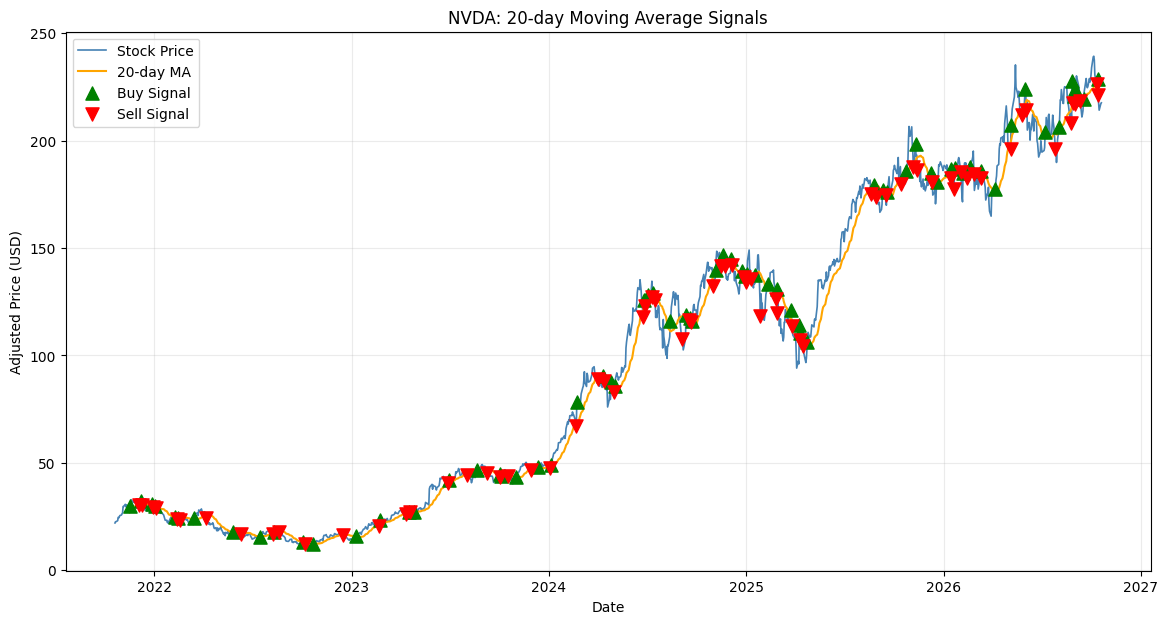


NVDA 最近5個交易日：


,Price,MA20,Signal
Date,,,
2026-10-14,221.300003,228.689501,不持有訊號
2026-10-15,217.229996,228.584001,不持有訊號
2026-10-16,214.130005,228.177001,不持有訊號
2026-10-19,217.089996,227.662501,不持有訊號
2026-10-20,217.546997,227.096351,不持有訊號


最新模型狀態： 不持有訊號


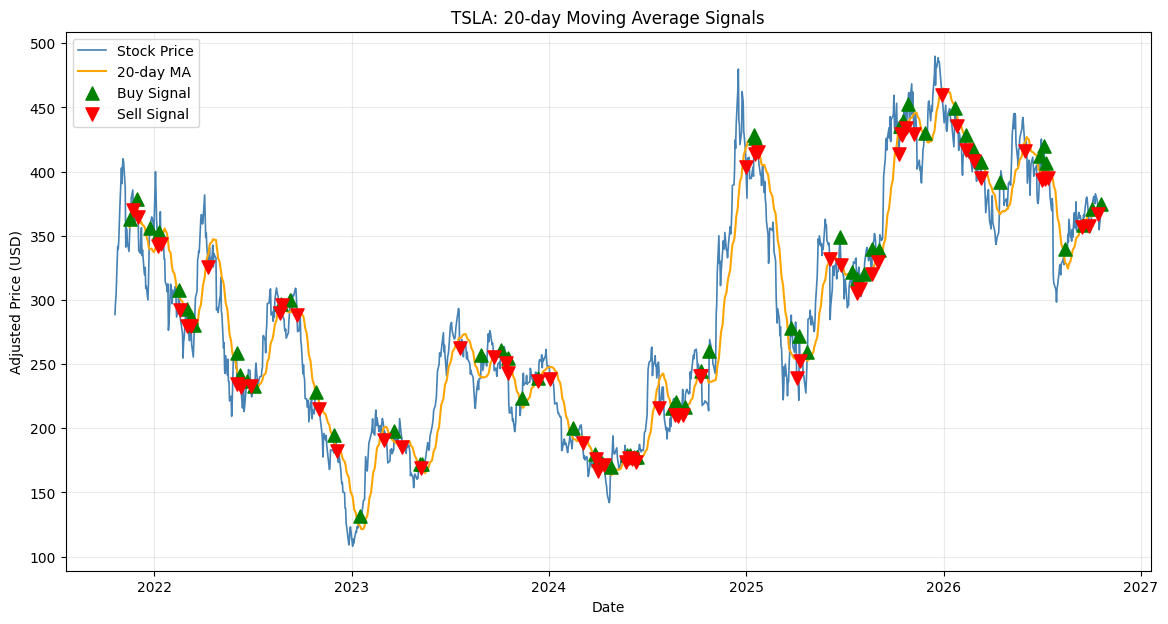


TSLA 最近5個交易日：


,Price,MA20,Signal
Date,,,
2026-10-14,367.160004,370.998999,不持有訊號
2026-10-15,362.440002,370.810999,不持有訊號
2026-10-16,354.720001,370.333499,不持有訊號
2026-10-19,368.059998,369.971500,不持有訊號
2026-10-20,374.619995,369.757500,持有訊號


最新模型狀態： 持有訊號


In [4]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

def show_signals(ticker):
    # 下載最近5年歷史股價
    df = yf.download(
        ticker,
        period="5y",
        auto_adjust=True,
        progress=False
    )

    if df.empty:
        print(f"{ticker}: 無法取得股價數據")
        return

    close = df["Close"].squeeze().dropna()

    # 計算20日移動平均線
    ma20 = close.rolling(window=20).mean()

    # 股價高於平均線：1；否則：0
    signal = (close > ma20).astype(int)

    # 只標記持倉狀態發生改變的日期
    change = signal.diff()

    buy_dates = close.index[change == 1]
    sell_dates = close.index[change == -1]

    # 繪圖
    plt.figure(figsize=(14, 7))
    plt.plot(close.index, close, label="Stock Price",
             color="steelblue", linewidth=1.2)
    plt.plot(ma20.index, ma20, label="20-day MA",
             color="orange", linewidth=1.5)

    # 買入訊號
    plt.scatter(
        buy_dates, close.loc[buy_dates],
        marker="^", color="green", s=90,
        label="Buy Signal", zorder=5
    )

    # 賣出訊號
    plt.scatter(
        sell_dates, close.loc[sell_dates],
        marker="v", color="red", s=90,
        label="Sell Signal", zorder=5
    )

    plt.title(f"{ticker}: 20-day Moving Average Signals")
    plt.xlabel("Date")
    plt.ylabel("Adjusted Price (USD)")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.show()

    print(f"\n{ticker} 最近5個交易日：")
    result = pd.DataFrame({
        "Price": close,
        "MA20": ma20,
        "Signal": signal.map({
            1: "持有訊號",
            0: "不持有訊號"
        })
    })
    display(result.tail())

    print("最新模型狀態：",
          "持有訊號" if signal.iloc[-1] == 1
          else "不持有訊號")

# 分析兩隻股票
show_signals("NVDA")
show_signals("TSLA")


===== NVDA 回測結果 =====


,20日平均線策略,買入並持有
總回報,187.87%,886.34%
年化回報,23.55%,58.06%
最大回撤,-54.20%,-66.34%


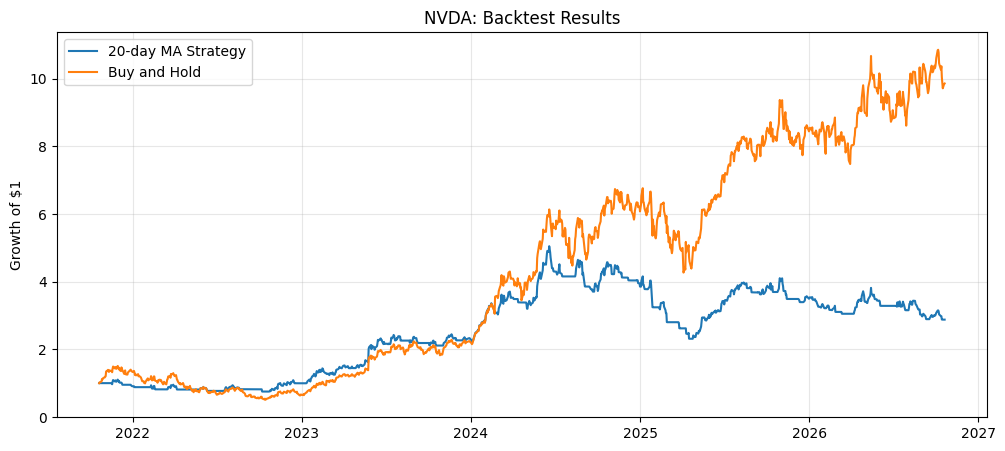

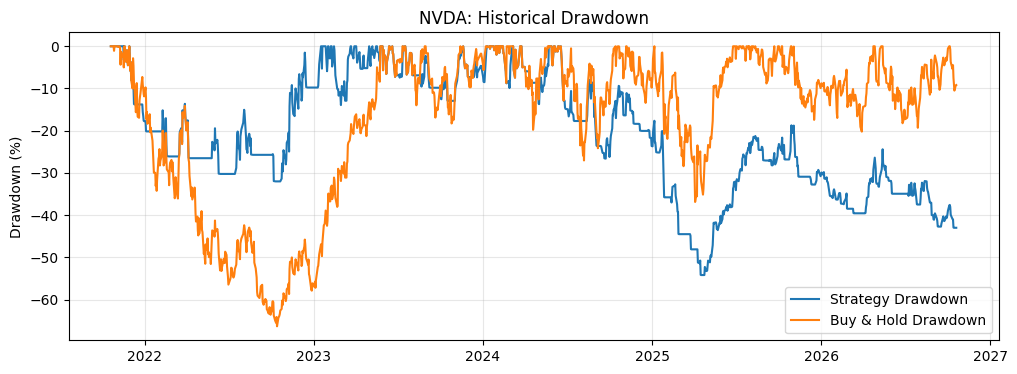


===== TSLA 回測結果 =====


,20日平均線策略,買入並持有
總回報,91.16%,29.54%
年化回報,13.84%,5.31%
最大回撤,-37.45%,-73.63%


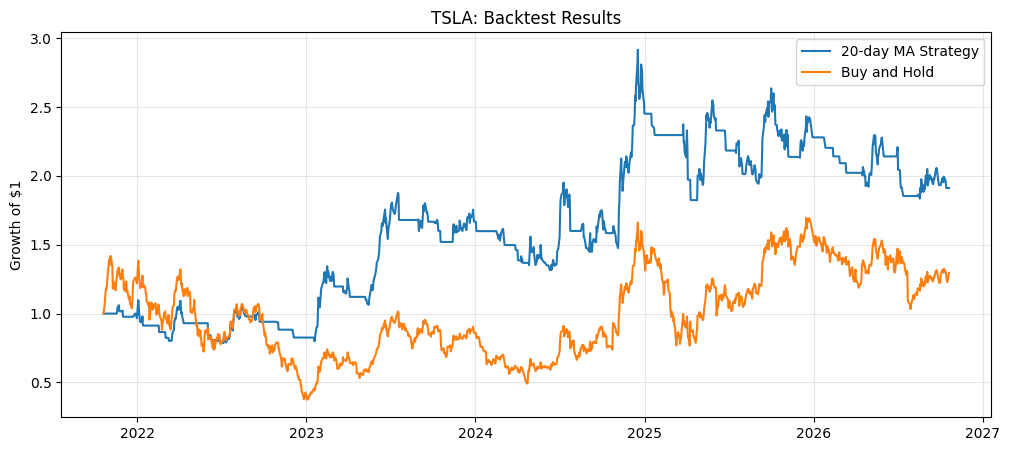

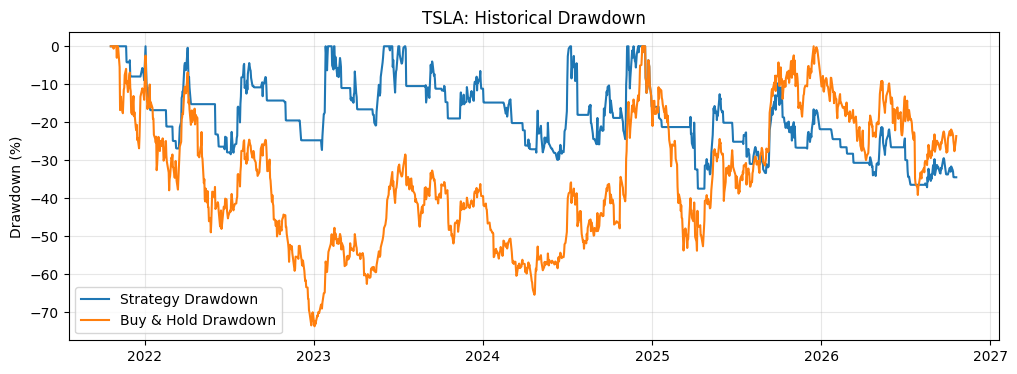

In [5]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def backtest(ticker, period="5y", cost=0.001):

    # 1. 下載歷史股價
    data = yf.Ticker(ticker).history(
        period=period,
        auto_adjust=True
    )

    if data.empty:
        print(f"{ticker}: 無法取得數據")
        return None

    close = data["Close"].dropna()

    # 2. 計算20日移動平均線
    ma20 = close.rolling(20).mean()

    # 股價高於20日平均線時產生持有訊號
    signal = (close > ma20).astype(int)

    # 訊號延後一天執行，避免偷看未來
    position = signal.shift(1).fillna(0)

    # 3. 計算每日股價回報
    daily_return = close.pct_change().fillna(0)

    # 4. 計算持倉變動及交易成本
    trades = position.diff().abs()
    trades.iloc[0] = position.iloc[0]
    trades = trades.fillna(0)

    # 假設每次買賣的單邊成本為0.1%
    trading_cost = trades * cost

    # 策略每日淨回報
    strategy_return = (
        position * daily_return - trading_cost
    )

    # 買入並持有：假設期初買入，並扣除一次買入成本
    buy_hold_return = daily_return.copy()
    buy_hold_return.iloc[0] = (
        (1 + buy_hold_return.iloc[0]) * (1 - cost) - 1
    )

    # 5. 計算累積資產曲線
    strategy_equity = (1 + strategy_return).cumprod()
    buy_hold_equity = (1 + buy_hold_return).cumprod()

    # 6. 計算總回報
    strategy_total = strategy_equity.iloc[-1] - 1
    buy_hold_total = buy_hold_equity.iloc[-1] - 1

    # 7. 計算最大回撤
    strategy_drawdown = (
        strategy_equity / strategy_equity.cummax() - 1
    )
    buy_hold_drawdown = (
        buy_hold_equity / buy_hold_equity.cummax() - 1
    )

    strategy_mdd = strategy_drawdown.min()
    buy_hold_mdd = buy_hold_drawdown.min()

    # 8. 計算年化回報
    years = (
        (close.index[-1] - close.index[0]).days / 365.25
    )

    strategy_cagr = (
        strategy_equity.iloc[-1] ** (1 / years) - 1
        if years > 0 else np.nan
    )
    buy_hold_cagr = (
        buy_hold_equity.iloc[-1] ** (1 / years) - 1
        if years > 0 else np.nan
    )

    # 9. 顯示結果
    results = pd.DataFrame({
        "20日平均線策略": [
            strategy_total,
            strategy_cagr,
            strategy_mdd
        ],
        "買入並持有": [
            buy_hold_total,
            buy_hold_cagr,
            buy_hold_mdd
        ]
    }, index=[
        "總回報",
        "年化回報",
        "最大回撤"
    ])

    print(f"\n===== {ticker} 回測結果 =====")
    display(results.style.format("{:.2%}"))

    # 10. 繪製資產曲線
    plt.figure(figsize=(12, 5))
    plt.plot(
        strategy_equity.index,
        strategy_equity,
        label="20-day MA Strategy"
    )
    plt.plot(
        buy_hold_equity.index,
        buy_hold_equity,
        label="Buy and Hold"
    )
    plt.title(f"{ticker}: Backtest Results")
    plt.ylabel("Growth of $1")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    # 11. 繪製回撤曲線
    plt.figure(figsize=(12, 4))
    plt.plot(
        strategy_drawdown.index,
        strategy_drawdown * 100,
        label="Strategy Drawdown"
    )
    plt.plot(
        buy_hold_drawdown.index,
        buy_hold_drawdown * 100,
        label="Buy & Hold Drawdown"
    )
    plt.title(f"{ticker}: Historical Drawdown")
    plt.ylabel("Drawdown (%)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    return results


# 分別測試 Nvidia 及 Tesla
nvda_results = backtest("NVDA")
tsla_results = backtest("TSLA")

最近5個交易日的收市價：


Ticker,NVDA,TSLA
Date,,
2026-10-14,221.300003,367.160004
2026-10-15,217.229996,362.440002
2026-10-16,214.130005,354.720001
2026-10-19,217.089996,368.059998
2026-10-20,217.315002,374.484985


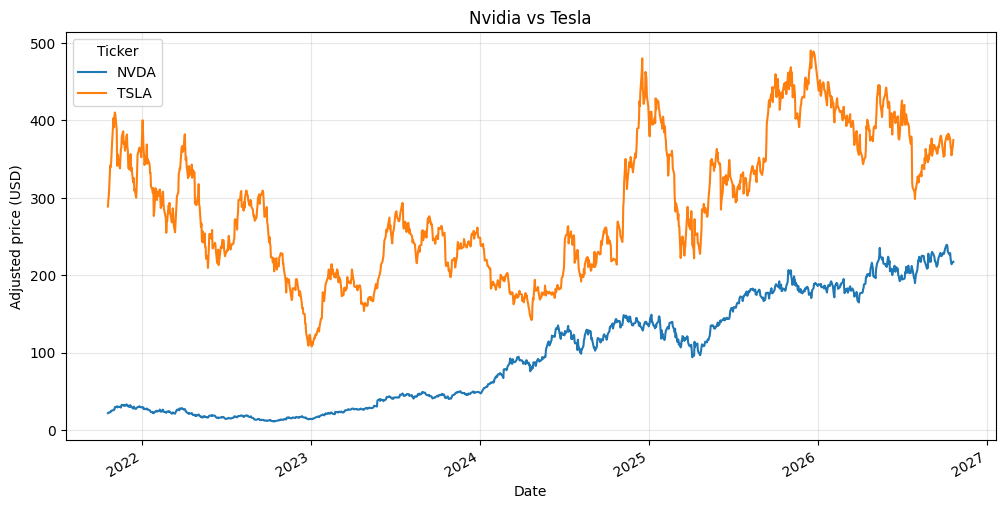

In [3]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

stocks = ["NVDA", "TSLA"]

prices = yf.download(
    stocks,
    period="5y",
    auto_adjust=True,
    progress=False
)

close = prices["Close"]

print("最近5個交易日的收市價：")
display(close.tail())

close.plot(figsize=(12, 6), title="Nvidia vs Tesla")
plt.ylabel("Adjusted price (USD)")
plt.grid(alpha=0.3)
plt.show()